# $1.$ $Classifier$

In [15]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

import pandas as pd

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target

df.rename(
    columns={
        'target': 'Species',
        'sepal length (cm)': 'SepalLengthCm',
        'sepal width (cm)': 'SepalWidthCm'
    },
    inplace=True
)

df.sample(10)


,SepalLengthCm,SepalWidthCm,petal length (cm),petal width (cm),Species
15,5.7,4.4,1.5,0.4,0
55,5.7,2.8,4.5,1.3,1
108,6.7,2.5,5.8,1.8,2
57,4.9,2.4,3.3,1.0,1
23,5.1,3.3,1.7,0.5,0
40,5.0,3.5,1.3,0.3,0
134,6.1,2.6,5.6,1.4,2
68,6.2,2.2,4.5,1.5,1
86,6.7,3.1,4.7,1.5,1
61,5.9,3.0,4.2,1.5,1


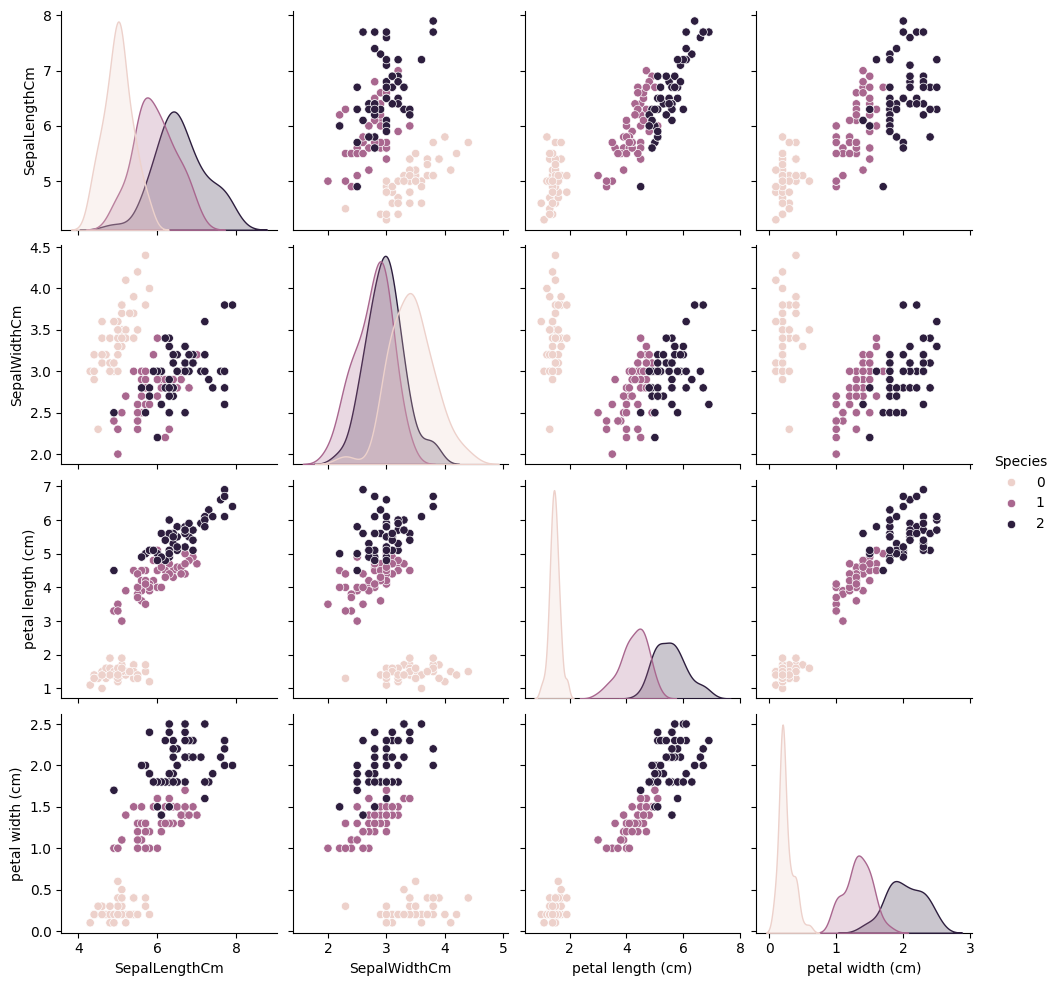

In [16]:
import seaborn as sns
sns.pairplot(df,hue='Species')

In [17]:
new_df = df[df['Species'] != 0][['SepalLengthCm','SepalWidthCm','Species']]

new_df.head()

,SepalLengthCm,SepalWidthCm,Species
50,7.0,3.2,1
51,6.4,3.2,1
52,6.9,3.1,1
53,5.5,2.3,1
54,6.5,2.8,1


In [18]:
new_df.shape

(100, 3)

In [19]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]


from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = KNeighborsClassifier()


estimators = [('lr',clf1),('rf',clf2),('knn',clf3)]


for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy')
    print(estimator[0],np.round(np.mean(x),2))

lr 0.81
rf 0.73
knn 0.76


# Hard Voting

In [20]:
from sklearn.ensemble import VotingClassifier

In [21]:
vc = VotingClassifier(estimators=estimators,voting='hard')
x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

0.77


# Soft Voting

In [22]:
vc1 = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc1,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

0.76


# Weighted Voting

In [23]:
for i in range(1,4):
    for j in range(1,4):
        for k in range(1,4):
            vc = VotingClassifier(estimators=estimators,voting='soft',weights=[i,j,k])
            x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
            print("for i={},j={},k={}".format(i,j,k),np.round(np.mean(x),2))

            

for i=1,j=1,k=1 0.77
for i=1,j=1,k=2 0.76
for i=1,j=1,k=3 0.75
for i=1,j=2,k=1 0.76
for i=1,j=2,k=2 0.75
for i=1,j=2,k=3 0.76
for i=1,j=3,k=1 0.74
for i=1,j=3,k=2 0.74
for i=1,j=3,k=3 0.75
for i=2,j=1,k=1 0.77
for i=2,j=1,k=2 0.77
for i=2,j=1,k=3 0.75
for i=2,j=2,k=1 0.77
for i=2,j=2,k=2 0.76
for i=2,j=2,k=3 0.76
for i=2,j=3,k=1 0.75
for i=2,j=3,k=2 0.76
for i=2,j=3,k=3 0.75
for i=3,j=1,k=1 0.79
for i=3,j=1,k=2 0.77
for i=3,j=1,k=3 0.78
for i=3,j=2,k=1 0.78
for i=3,j=2,k=2 0.77
for i=3,j=2,k=3 0.77
for i=3,j=3,k=1 0.75
for i=3,j=3,k=2 0.77
for i=3,j=3,k=3 0.75


# Classifiers of Same Algo

In [24]:
from sklearn.svm import SVC
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=2)

svm1 = SVC(probability=True, kernel='poly', degree=1)
svm2 = SVC(probability=True, kernel='poly', degree=2)
svm3 = SVC(probability=True, kernel='poly', degree=3)
svm4 = SVC(probability=True, kernel='poly', degree=4)
svm5 = SVC(probability=True, kernel='poly', degree=5)

estimators = [('svm1',svm1),('svm2',svm2),('svm3',svm3),('svm4',svm4),('svm5',svm5)]

for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy')
    print(estimator[0],np.round(np.mean(x),2))



svm1 0.85
svm2 0.85
svm3 0.89
svm4 0.81
svm5 0.86


In [25]:
vc1 = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc1,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

0.93


# $2.$ $Regressor$

In [26]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

data = fetch_california_housing(as_frame=True)
df = data.frame

df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score
     

lr = LinearRegression()
dt = DecisionTreeRegressor()
svr = SVR()
     

estimators = [('lr',lr),('dt',dt),('svr',svr)]
     

for estimator in estimators:
  scores = cross_val_score(estimator[1],X,y,scoring='r2',cv=10)
  print(estimator[0],np.round(np.mean(scores),2))

lr 0.52
dt 0.07
svr 0.73


In [28]:
from sklearn.ensemble import VotingRegressor
     

vr = VotingRegressor(estimators)
scores = cross_val_score(vr,X,y,scoring='r2',cv=10)
print("Voting Regressor",np.round(np.mean(scores),2))
     

Voting Regressor 0.6


In [29]:
for i in range(1,4):
  for j in range(1,4):
    for k in range(1,4):
      vr = VotingRegressor(estimators,weights=[i,j,k])
      scores = cross_val_score(vr,X,y,scoring='r2',cv=10)
      print("For i={},j={},k={}".format(i,j,k),np.round(np.mean(scores),2))


For i=1,j=1,k=1 0.61
For i=1,j=1,k=2 0.65
For i=1,j=1,k=3 0.68
For i=1,j=2,k=1 0.5
For i=1,j=2,k=2 0.59
For i=1,j=2,k=3 0.62
For i=1,j=3,k=1 0.44
For i=1,j=3,k=2 0.53
For i=1,j=3,k=3 0.59
For i=2,j=1,k=1 0.59
For i=2,j=1,k=2 0.64
For i=2,j=1,k=3 0.67
For i=2,j=2,k=1 0.54
For i=2,j=2,k=2 0.6
For i=2,j=2,k=3 0.63
For i=2,j=3,k=1 0.48
For i=2,j=3,k=2 0.54
For i=2,j=3,k=3 0.59
For i=3,j=1,k=1 0.59
For i=3,j=1,k=2 0.64
For i=3,j=1,k=3 0.66
For i=3,j=2,k=1 0.55
For i=3,j=2,k=2 0.6
For i=3,j=2,k=3 0.63
For i=3,j=3,k=1 0.52
For i=3,j=3,k=2 0.58
For i=3,j=3,k=3 0.6


In [30]:
# using the same algorithm

dt1 = DecisionTreeRegressor(max_depth=1)
dt2 = DecisionTreeRegressor(max_depth=3)
dt3 = DecisionTreeRegressor(max_depth=5)
dt4 = DecisionTreeRegressor(max_depth=7)
dt5 = DecisionTreeRegressor(max_depth=None)
     

estimators = [('dt1',dt1),('dt2',dt2),('dt3',dt3),('dt4',dt4),('dt5',dt5)]
     

for estimator in estimators:
  scores = cross_val_score(estimator[1],X,y,scoring='r2',cv=10)
  print(estimator[0],np.round(np.mean(scores),2))
     

dt1 0.13
dt2 0.21
dt3 0.29
dt4 0.22
dt5 0.0


In [31]:
vr = VotingRegressor(estimators)
scores = cross_val_score(vr,X,y,scoring='r2',cv=10)
print("Voting Regressor",np.round(np.mean(scores),2))

Voting Regressor 0.37
